<a href="https://colab.research.google.com/github/msolanki0709/manish_solanki_nic/blob/main/Excercise2_Manish_Solanki.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Resized image 2 to match image 1 dimensions: 738x354
Saved: output_original_1.png, output_original_2.png, output_blended.png


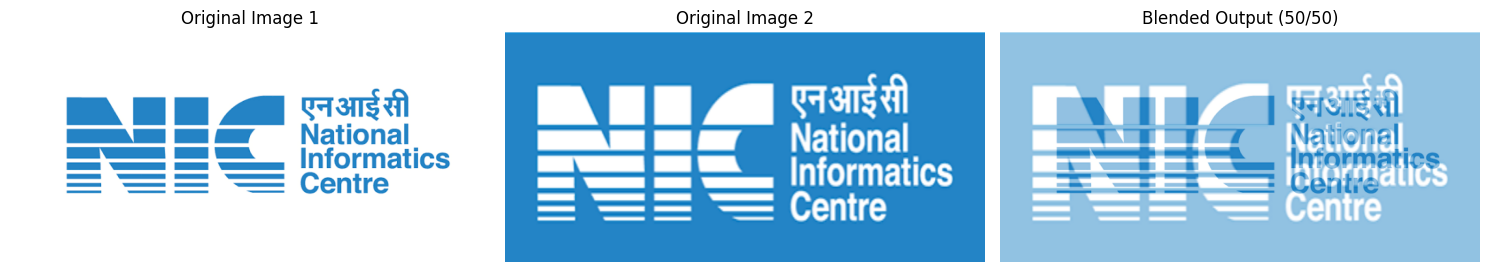

In [3]:
import cv2
import matplotlib.pyplot as plt

# 1. Load the uploaded PNG images from Colab's /content/ directory
img1_path = '/content/image1.png'
img2_path = '/content/image2.png'

img1 = cv2.imread(img1_path)
img2 = cv2.imread(img2_path)

if img1 is None or img2 is None:
    raise FileNotFoundError("Ensure 'image1.png' and 'image2.png' are uploaded in /content/.")

# Resize img2 to match the dimensions (width, height) of img1 if they differ
if img1.shape != img2.shape:
    img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))
    print(f"Resized image 2 to match image 1 dimensions: {img1.shape[1]}x{img1.shape[0]}")

# 2. Perform weighted image blending
alpha = 0.5  # Weight for image 1
beta = 0.5   # Weight for image 2
gamma = 0.0  # Scalar added to each sum
blended_img = cv2.addWeighted(img1, alpha, img2, beta, gamma)

# 3. Save the outputs to the same /content/ directory
cv2.imwrite('/content/output_original_1.png', img1)
cv2.imwrite('/content/output_original_2.png', img2)
cv2.imwrite('/content/output_blended.png', blended_img)
print("Saved: output_original_1.png, output_original_2.png, output_blended.png")

# Convert BGR (OpenCV default) to RGB for accurate Matplotlib display
img1_rgb = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
blended_rgb = cv2.cvtColor(blended_img, cv2.COLOR_BGR2RGB)

# Display all three images side-by-side
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
titles = ['Original Image 1', 'Original Image 2', 'Blended Output (50/50)']
images = [img1_rgb, img2_rgb, blended_rgb]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title, fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.show()